# Ajustar el modelo y el punto de corte

Proyecto individual tutorado con Pablo Valenzuela. Se conservan los artefactos anteriores. Esta búsqueda nace después de haber observado 2024 en v1 y v2: su reevaluación temporal sigue siendo **exploratoria**. Mejorar un score de clasificación no equivale a demostrar certeza individual ni precisión futura.

## 1. Objetivo y protocolo registrado

Se busca mayor F1 macro con hiperparámetros y corte de clasificación elegidos usando respuestas hasta 2017. La definición de la respuesta permanece en crecimiento anual ≥1%. Se comparan 19 configuraciones de Random Forest, Logistic Regression y Gradient Boosting, con nueve cortes (0,30 a 0,70): 171 combinaciones.

Se usa CV anidada: cinco particiones externas reservan comunas para evaluar el procedimiento; en cada ajuste externo, cuatro particiones internas eligen configuración y corte sin utilizar las comunas externas. Después se elige la configuración final con cinco particiones de las 314 comunas anteriores a 2024. La elección queda guardada antes de la reevaluación 2017–2024. La CV es entre comunas de una época y los datos ya participaron en versiones previas; no es una prueba temporal final nueva.

Para reproducir la búsqueda completa: `.venv/bin/python experiments/tuning_crecimiento.py`. Este notebook vuelve a entrenar el candidato seleccionado y contrasta las salidas guardadas; muestra la búsqueda completa y las particiones anidadas sin ejecutar otra vez sus 475 ajustes internos.

In [1]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import StratifiedKFold,FixedThresholdClassifier
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/'experiments').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'experiments'))
import tuning_crecimiento as t
import crecimiento_v2 as v2
import crecimiento_censal as v1
protocol=json.loads(t.PROTOCOL.read_text())
closed=json.loads((t.OUT/'seleccion_cerrada.json').read_text())
summary=json.loads((t.OUT/'resumen.json').read_text())
profiles=pd.read_csv(v2.OUT/'perfiles_censales.csv')
core=closed['core_codes']
all_codes=sorted(core+v2.RECOVERED)
print('Configuración:',closed['candidate'])
print('Corte sobre score:',closed['threshold'],'; umbral de respuesta:',protocol['target_threshold_annual_growth'])
print('Selección usó respuestas de 2024:',closed['selection_used_2024_labels'])
print('2024 conocido previamente:',closed['2024_already_observed_in_prior_versions'])

Configuración: {'id': 'bosque_d8_h5_sin_pesos', 'algorithm': 'RandomForestClassifier', 'features': ['log_poblacion', 'proporcion_menores_15', 'proporcion_65_mas', 'crecimiento_previo'], 'params': {'n_estimators': 300, 'max_depth': 8, 'min_samples_leaf': 5, 'class_weight': None, 'n_jobs': 2, 'random_state': 2025}}
Corte sobre score: 0.45 ; umbral de respuesta: 0.01
Selección usó respuestas de 2024: False
2024 conocido previamente: True


## 2. Preparación y muestra

Unidad de entrenamiento: comuna-período. Los cientos de miles de residentes no son cientos de miles de ejemplos independientes: se ajusta con 314 comunas. Se conservan las proporciones de menores y mayores, población logarítmica y crecimiento anterior; algunas alternativas incluyen cambios anuales de proporciones de edad. El escalado logístico se ajusta dentro de cada partición.

Temuco y Padre Las Casas permanecen como aplicaciones adicionales fuera de la selección histórica. Padre Las Casas utiliza 2002 y 2017, sin incorporar 1992. La recuperación territorial y la residencia habitual identificada mantienen las limitaciones documentadas en v2.

In [2]:
history=profiles.query('year<=2017').copy()
_,X,_=v2.inputs(history,1992,2002,core)
y=np.asarray(v2.labels(history,2002,2017,core)[0])
assert len(X)==314 and set(history.year)=={1992,2002,2017}
display(X.describe().T)
print('Clases:',np.bincount(y))

,count,mean,std,min,25%,50%,75%,max
log_poblacion,314.0,9.706873,1.406373,3.332205,8.992649,9.667013,10.547774,13.055929
proporcion_menores_15,314.0,0.265654,0.032861,0.035971,0.256264,0.269921,0.281736,0.370370
proporcion_65_mas,314.0,0.089163,0.023676,0.000000,0.076387,0.089787,0.103478,0.170817
crecimiento_previo,314.0,0.007097,0.018667,-0.133380,-0.001900,0.005980,0.015024,0.118767
cambio_menores_15_anual,314.0,-0.003861,0.001943,-0.017138,-0.004602,-0.003841,-0.003102,0.013143
cambio_65_mas_anual,314.0,0.001808,0.001000,-0.001420,0.001261,0.001782,0.002330,0.005495


Clases: [217  97]


## 3. Evaluación externa del procedimiento de ajuste

Las métricas externas se calculan con modelos y cortes elegidos en cada parte interna. Pueden diferir de la métrica usada para escoger el modelo final. El Random Forest v2 fijo y la continuidad previa se comparan con las mismas comunas externas; no se presentan las mejores métricas internas como si fueran externas.

In [3]:
folds=json.loads((t.OUT/'particiones_anidadas.json').read_text())
reserved=[]
for fold in folds:
    train,valid=set(fold['train']),set(fold['validation'])
    assert not train&valid and train|valid==set(core)
    for inner in fold['inner_folds']:
        fit,selection=set(inner['train']),set(inner['validation'])
        assert not fit&selection and fit|selection==train
        assert not (fit|selection)&valid
    reserved+=fold['validation']
assert sorted(reserved)==sorted(core)
display(pd.DataFrame([{'partición':i+1,'candidato':f['chosen']['id'],'corte':f['threshold'],'F1 externo':f['external_metrics']['f1_macro']} for i,f in enumerate(folds)]))
display(pd.DataFrame([{'alternativa':k,'F1 macro externo':r['f1_macro'],'aciertos':round(r['accuracy']*r['n']),'n':r['n']} for k,r in summary['validation'].items() if isinstance(r,dict)]))

,partición,candidato,corte,F1 externo
0,1,bosque_d8_h5_balanceado,0.55,0.698565
1,2,bosque_d3_h15_sin_pesos,0.45,0.789554
2,3,boost_d2_t0.05,0.30,0.706173
3,4,bosque_d8_h5_balanceado,0.45,0.805556
4,5,boost_seis,0.45,0.747967


,alternativa,F1 macro externo,aciertos,n
0,tuneado,0.749213,246,314
1,v2_fijo,0.758592,247,314
2,persistencia,0.759125,245,314


## 4. Elección final y reproducción de sus scores

Se muestran las 171 combinaciones registradas. La media de F1 por partición, seguida de exactitud, exactitud balanceada y simplicidad, determina la elección. El corte se busca con predicciones fuera del ajuste; no con scores calculados sobre las mismas filas usadas para entrenar. Las probabilidades originales se mantienen al cambiar el corte: cambiar etiquetas por sí solo no calibra probabilidades.

In [4]:
search=pd.read_csv(t.OUT/'busqueda_final.csv')
best=max(search.to_dict('records'),key=t.rank)
assert len(search)==171 and best['candidate']==closed['candidate']['id']
assert best['threshold']==closed['threshold']
display(search.sort_values('selection_f1_mean',ascending=False).head(15))
selected_scores=np.full(len(y),np.nan)
for fit,valid in StratifiedKFold(**protocol['final_selection_validation']).split(X,y):
    fitted=t.make_model(closed['candidate']).fit(X.iloc[fit],y[fit])
    selected_scores[valid]=fitted.predict_proba(X.iloc[valid])[:,1]
recorded=pd.read_csv(t.OUT/'scores_seleccion.csv')
np.testing.assert_allclose(selected_scores,recorded[closed['candidate']['id']])
print('Scores de selección reproducidos sin etiquetas de 2024.')

,candidate,algorithm,features,threshold,order,selection_f1_mean,selection_f1_std,accuracy_mean,balanced_accuracy_mean,f1_macro,accuracy,balanced_accuracy
48,bosque_d8_h5_sin_pesos,RandomForestClassifier,4,0.45,5,0.779057,0.065093,0.815463,0.772757,0.778475,0.815287,0.772293
122,logistica_c1_balanceada,LogisticRegression,4,0.55,13,0.778651,0.052101,0.812340,0.776044,0.778044,0.812102,0.775690
60,bosque_d8_h5_balanceado,RandomForestClassifier,4,0.60,6,0.774591,0.045235,0.815412,0.764207,0.774157,0.815287,0.763742
91,logistica_c0.1_sin_pesos,LogisticRegression,4,0.35,10,0.773397,0.049682,0.805940,0.774278,0.773151,0.805732,0.773932
144,boost_d2_t0.05,GradientBoostingClassifier,4,0.30,16,0.769154,0.062804,0.789811,0.788088,0.768136,0.789809,0.788066
67,bosque_d8_h15_sin_pesos,RandomForestClassifier,4,0.50,7,0.767897,0.065748,0.812340,0.756006,0.767923,0.812102,0.755737
153,boost_d2_t0.1,GradientBoostingClassifier,4,0.30,17,0.767768,0.075316,0.789759,0.782318,0.766084,0.789809,0.782365
109,logistica_c1_sin_pesos,LogisticRegression,4,0.35,12,0.764758,0.028580,0.796313,0.769818,0.765234,0.796178,0.769870
47,bosque_d8_h5_sin_pesos,RandomForestClassifier,4,0.40,5,0.764370,0.062702,0.796365,0.767248,0.763965,0.796178,0.767020
110,logistica_c1_sin_pesos,LogisticRegression,4,0.40,12,0.764171,0.048213,0.809114,0.753892,0.764794,0.808917,0.753432


Scores de selección reproducidos sin etiquetas de 2024.


## 5. Reevaluación temporal exploratoria de 2024

Se mantiene el denominador de 314 comunas para comparar con v2 y continuidad. También se muestra el ajuste del corte del Random Forest v2 como comparación predefinida: su corte se eligió antes de consultar 2024. No se ajustan parámetros después de esta reevaluación. Se informan falsas alertas y casos de crecimiento alto omitidos, además de aciertos y F1.

,alternativa,F1 macro,aciertos,n,falsas alertas,omitidos
0,tuneado,0.613768,193,314,75,46
1,v2,0.641879,205,314,89,20
2,solo_corte_v2,0.605523,201,314,17,96
3,persistencia,0.663001,213,314,24,77


,Predice <1%,Predice ≥1%
Real <1%,89,75
Real ≥1%,46,104


,precision,recall,f1-score,support
Menor que 1% anual,0.659259,0.542683,0.595318,164.00000
Al menos 1% anual,0.581006,0.693333,0.632219,150.00000
accuracy,0.614650,0.614650,0.614650,0.61465
macro avg,0.620132,0.618008,0.613768,314.00000
weighted avg,0.621877,0.614650,0.612946,314.00000


Comparación pareada con tendencia: {'method': 'Bootstrap pareado por región, 1000 réplicas; intervalo exploratorio', 'delta_f1_macro': -0.049232341577267746, 'interval_95': [-0.13409914695801106, 0.058678325070298555], 'new_correct_baseline_wrong': 55, 'new_wrong_baseline_correct': 75}


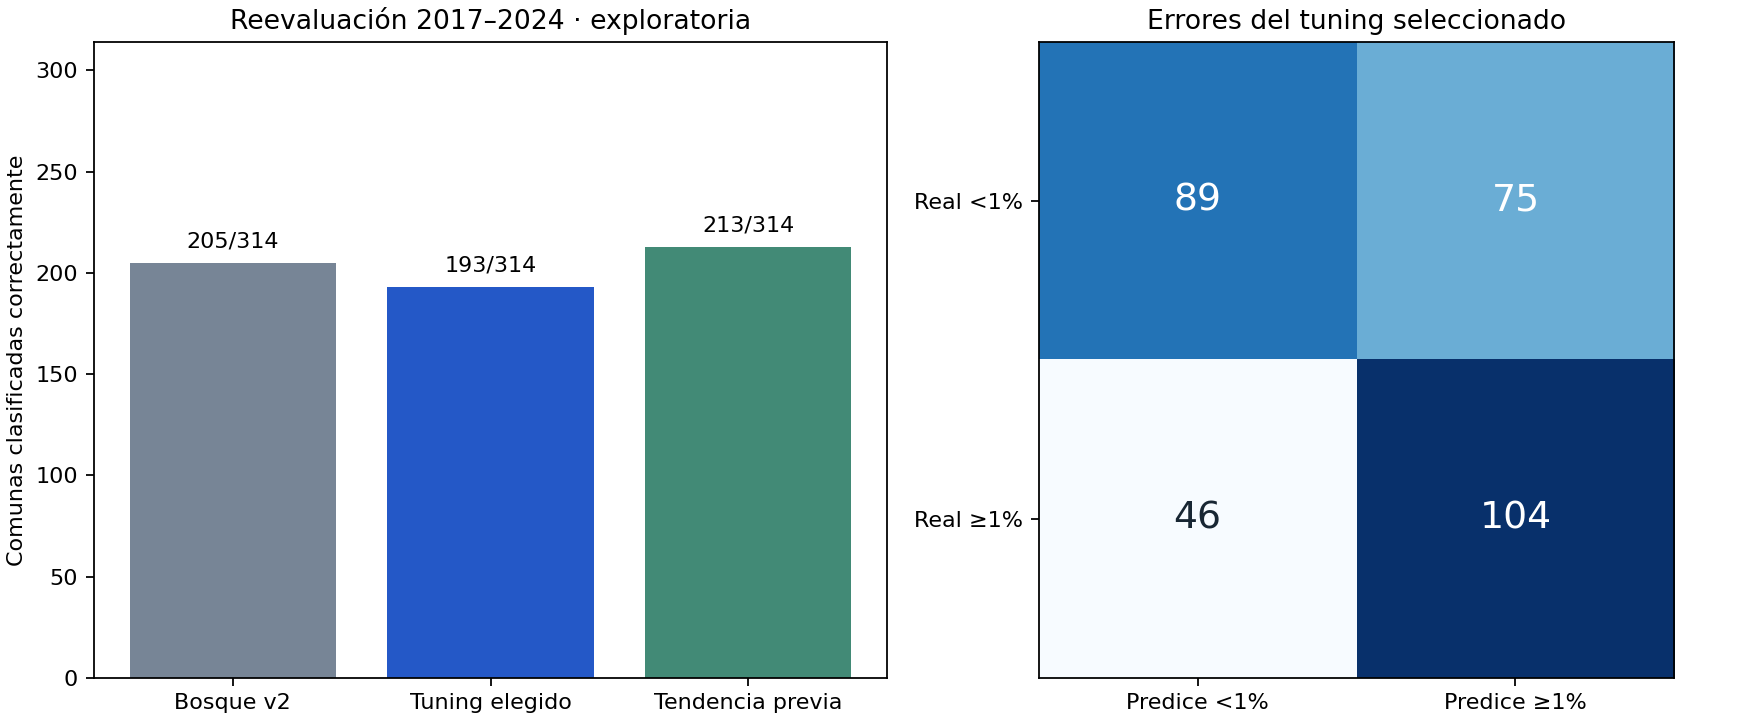

,name,previous_rate,score,score_threshold,predicted_class,actual_class,actual_rate,correct
155,Temuco,0.008643,0.404523,0.45,0,0,0.006116,True
164,Padre Las Casas,0.015545,0.548043,0.45,1,1,0.010612,True


In [5]:
historical=FixedThresholdClassifier(t.make_model(closed['candidate']),threshold=closed['threshold'],response_method='predict_proba').fit(X,y)
initial,X_test,old=v2.inputs(profiles,2002,2017,all_codes)
y_test=np.asarray(v2.labels(profiles,2017,2024,all_codes)[0])
saved=joblib.load(t.OUT/'clasificador_historico.joblib')
np.testing.assert_allclose(historical.predict_proba(X_test),saved.predict_proba(X_test))
np.testing.assert_array_equal(historical.predict(X_test),saved.predict(X_test))
display(pd.DataFrame([{'alternativa':k,'F1 macro':r['f1_macro'],'aciertos':round(r['accuracy']*r['n']),'n':r['n'],'falsas alertas':r['confusion'][0][1],'omitidos':r['confusion'][1][0]} for k,r in summary['test'].items()]))
display(pd.DataFrame(summary['test']['tuneado']['confusion'],index=['Real <1%','Real ≥1%'],columns=['Predice <1%','Predice ≥1%']))
display(pd.DataFrame(summary['test']['tuneado']['classes']).T)
print('Comparación pareada con tendencia:',summary['paired_vs_persistence'])
display(Image(filename=str(t.OUT/'evaluacion.png')))
individual=pd.read_csv(t.OUT/'predicciones_historicas.csv')
display(individual.loc[individual.code.isin(v2.RECOVERED),['name','previous_rate','score','score_threshold','predicted_class','actual_class','actual_rate','correct']])

## 6. Ajuste separado para 2031

El escenario futuro utiliza otro modelo, ajustado con 630 ejemplos y respuestas conocidas hasta 2024. Se conserva la configuración y corte seleccionados con la etapa anterior. El score es una salida sin calibrar; no se etiqueta como porcentaje de certeza. No existe resultado observado de 2031 para comprobarlo. El cambio de época, de duraciones y de proporción de clases sigue limitando la transferencia.

In [6]:
future=FixedThresholdClassifier(t.make_model(closed['candidate']),threshold=closed['threshold'],response_method='predict_proba').fit(pd.concat([X,X_test]),np.concatenate([y,y_test]))
_,X_future,_=v2.inputs(profiles,2017,2024,all_codes)
saved_future=joblib.load(t.OUT/'clasificador_futuro.joblib')
np.testing.assert_allclose(future.predict_proba(X_future),saved_future.predict_proba(X_future))
records=json.loads((t.OUT/'modelo.json').read_text())['records']
assert all(r['forecast']['verified']==False and 'actual_class' not in r['forecast'] for r in records)
display(pd.DataFrame([{'comuna':r['name'],'clase experimental':r['forecast']['predicted_class'],'score sin calibrar':r['forecast']['score'],'corte':r['forecast']['score_threshold']} for r in records if r['recovered']]))
print('Ajuste histórico: 314; ajuste futuro:',len(X)+len(X_test))

,comuna,clase experimental,score sin calibrar,corte
0,Temuco,0,0.407828,0.45
1,Padre Las Casas,1,0.703575,0.45


Ajuste histórico: 314; ajuste futuro: 630


## 7. Interpretación y fuentes

Una mejora de exactitud sobre 2024 no demuestra automáticamente precisión futura. La selección se hace con datos previos, pero el diseño del experimento ya conoce los resultados de versiones anteriores. Más parámetros tampoco añaden épocas ni muestras independientes. Si el tuning no mejora, se conserva ese resultado negativo; no se continúa buscando sobre 2024 hasta obtener una cifra mayor.

Fuentes: [Censos del INE](https://www.ine.gob.cl/estadisticas-por-tema/demografia-y-poblacion/censo-de-poblacion-y-vivienda). Misma preparación, exclusiones y atribución INE CC BY-SA 4.0 de v2; fuentes exactas y hashes en `data/raw/ine/crecimiento`. Método: [ajuste de cortes de scikit-learn 1.7](https://scikit-learn.org/1.7/modules/classification_threshold.html) y [validación cruzada](https://scikit-learn.org/1.7/modules/cross_validation.html).

La tasa anual que define la clase y el corte sobre el score del modelo son diferentes. Un score alto sin calibración no garantiza una probabilidad correcta para una comuna. No se presenta el escenario como una proyección oficial.